# Transformer-based modeling for complaint triage and sentiment
### Companion to `01_complaint_analysis.ipynb`

Notebook 01 built a TF-IDF + Logistic Regression department classifier and scored sentiment with VADER. This notebook brings in **pretrained transformers** for both tasks:

| Part | Model | Question |
|---|---|---|
| **A. Department classification** | Fine-tuned **DistilBERT** (`distilbert-base-uncased`, 66M parameters) | Does a contextual model route complaints better than TF-IDF on the *same* train/test split? |
| **B. Sentiment** | **RoBERTa sentiment** (`cardiffnlp/twitter-roberta-base-sentiment-latest`, 3 classes) | Does an independent transformer agree with the domain-adjusted VADER scores? |

**Run order:** run notebook 01 first. It writes `outputs/split_ids.csv`, `outputs/tfidf_metrics.json` and `outputs/complaints_scored.csv`, which this notebook reads.

**Hardware:** a CUDA GPU is strongly recommended (fine-tuning takes a few minutes on a modern GPU and much longer on CPU). The first run downloads about 750 MB of model weights from Hugging Face.

## 0. Setup

In [1]:
import os
import json
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from scipy.stats import spearmanr

# ---- configuration --------------------------------------------------------------------------
CLASSIFIER_CHECKPOINT = os.environ.get("CLASSIFIER_CHECKPOINT", "distilbert-base-uncased")
SENTIMENT_CHECKPOINT = os.environ.get("SENTIMENT_CHECKPOINT", "cardiffnlp/twitter-roberta-base-sentiment-latest")
MAX_LEN = 384          # tokens per complaint for classification (covers ~75% of complaints in full)
EPOCHS = 4
BATCH_SIZE = 16
LEARNING_RATE = 3e-5
WARMUP_FRACTION = 0.1
RANDOM_STATE = 42
QUICK_RUN = os.environ.get("QUICK_RUN") == "1"   # tiny smoke test, not for real results
if QUICK_RUN:
    MAX_LEN, EPOCHS = 128, 1

DATA_PATH = Path("data/banking_complaints_2023.xlsx")
OUT_DIR, FIG_DIR = Path("outputs"), Path("figures")
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if USE_AMP and torch.cuda.is_bf16_supported() else torch.float16
print(f"torch {torch.__version__} | device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
print(f"Classifier: {CLASSIFIER_CHECKPOINT} | Sentiment: {SENTIMENT_CHECKPOINT} | QUICK_RUN={QUICK_RUN}")

torch 2.11.0+cu128 | device: cuda (NVIDIA GeForce RTX 5060 Ti)
Classifier: distilbert-base-uncased | Sentiment: cardiffnlp/twitter-roberta-base-sentiment-latest | QUICK_RUN=False


In [2]:
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, RED, GRAY = "#2a78d6", "#eb6834", "#e34948", "#898781"
SEQ_BLUE = mpl.colors.LinearSegmentedColormap.from_list(
    "seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10, "legend.frameon": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE), "figure.dpi": 110, "savefig.bbox": "tight", "savefig.dpi": 150,
})
save = lambda name: plt.savefig(FIG_DIR / f"{name}.png")

## 1. Data: same complaints, same split as notebook 01

Transformers read **natural text**. Their tokenizers and attention layers rely on word order, stopwords, negation and punctuation, which is exactly what the TF-IDF preprocessing removed. So the input here is the raw complaint with only the `XXXX` anonymization masks stripped (the same light cleanup VADER got). The train/test assignment is loaded from notebook 01, so both models are scored on the identical 1,397 test complaints.

In [3]:
df = pd.read_excel(DATA_PATH)
df["Complaint ID"] = df["Complaint ID"].astype(str)

def light_clean(text):
    text = re.sub(r"\bX{2,}(/X{2,})*\b", " ", str(text))
    text = re.sub(r"[{}]", "", text)
    return re.sub(r"\s+", " ", text).strip()

df["text"] = df["Complaint Description"].map(light_clean)

split = pd.read_csv(OUT_DIR / "split_ids.csv", dtype={"Complaint ID": str})
data = df.merge(split, on="Complaint ID", how="inner")
train_full = data[data["split"] == "train"].reset_index(drop=True)
test = data[data["split"] == "test"].reset_index(drop=True)

# carve a validation set out of TRAIN for epoch selection; the test set is touched once at the end
train, val = train_test_split(train_full, test_size=0.1, stratify=train_full["Department"], random_state=RANDOM_STATE)
if QUICK_RUN:
    train = train.groupby("Department").head(40)
    val, test = val.head(120), test.head(200)

LABELS = sorted(data["Department"].unique())
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,} | classes: {LABELS}")

train 5,028 | val 559 | test 1,397 | classes: ['CASA', 'Credit Cards', 'Credit Reports', 'Loans', 'Mortgage', 'Others', 'Remittance']


## Part A. Fine-tuning DistilBERT for department classification

**Why DistilBERT:** it keeps about 97% of BERT's language understanding at 60% of the size and runs roughly twice as fast. That's a reasonable fit for a triage service that has to score complaints as they arrive.

**Setup**
* Tokenize to at most `MAX_LEN` tokens (truncating the tail of long complaints).
* Add a classification head (linear layer on the `[CLS]` representation) with 7 outputs.
* Train with AdamW, linear warmup/decay, and **class-weighted cross-entropy**. The weights are the same "balanced" weighting the Logistic Regression used, so the small Others and Remittance classes count fairly.
* Keep the epoch with the best **validation macro-F1**, then evaluate once on test.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(CLASSIFIER_CHECKPOINT)

token_lengths = [len(ids) for ids in tokenizer(test["text"].tolist(), truncation=False)["input_ids"]]
print(f"Test-set token lengths: median {np.median(token_lengths):.0f}, 75th pct {np.percentile(token_lengths, 75):.0f}, "
      f"share fitting in {MAX_LEN}: {np.mean(np.array(token_lengths) <= MAX_LEN):.0%}")

class ComplaintDataset(Dataset):
    def __init__(self, frame):
        self.enc = tokenizer(frame["text"].tolist(), truncation=True, max_length=MAX_LEN)
        self.labels = frame["Department"].map(label2id).tolist()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item

def collate(batch):
    labels = torch.tensor([b.pop("labels") for b in batch])
    padded = tokenizer.pad(batch, return_tensors="pt")
    padded["labels"] = labels
    return padded

train_dl = DataLoader(ComplaintDataset(train), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
val_dl = DataLoader(ComplaintDataset(val), batch_size=BATCH_SIZE * 2, collate_fn=collate)
test_dl = DataLoader(ComplaintDataset(test), batch_size=BATCH_SIZE * 2, collate_fn=collate)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (531 > 512). Running this sequence through the model will result in indexing errors


Test-set token lengths: median 169, 75th pct 302, share fitting in 384: 82%


In [5]:
model = AutoModelForSequenceClassification.from_pretrained(
    CLASSIFIER_CHECKPOINT, num_labels=len(LABELS), id2label=id2label, label2id=label2id).to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters())/1e6:.1f}M")

class_weights = compute_class_weight("balanced", classes=np.arange(len(LABELS)),
                                     y=train["Department"].map(label2id).values)
loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float, device=DEVICE))
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
total_steps = len(train_dl) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_FRACTION * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)

@torch.no_grad()
def predict(dl):
    model.eval()
    all_logits, all_labels = [], []
    for batch in dl:
        labels = batch.pop("labels")
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            logits = model(**batch).logits
        all_logits.append(logits.float().cpu())
        all_labels.append(labels)
    return torch.cat(all_logits), torch.cat(all_labels).numpy()

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parameters: 67.0M


In [6]:
history, best_f1, best_state = [], -1.0, None
t_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
    for step, batch in enumerate(train_dl, 1):
        labels = batch.pop("labels").to(DEVICE)
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            logits = model(**batch).logits
        loss = loss_fn(logits.float(), labels)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        running += loss.item()

    val_logits, val_true = predict(val_dl)
    val_pred = val_logits.argmax(1).numpy()
    row = {"epoch": epoch, "train_loss": running / len(train_dl),
           "val_accuracy": accuracy_score(val_true, val_pred),
           "val_macro_f1": f1_score(val_true, val_pred, average="macro"),
           "minutes": (time.perf_counter() - t_start) / 60}
    history.append(row)
    print(f"epoch {epoch}: loss {row['train_loss']:.4f} | val acc {row['val_accuracy']:.3f} | "
          f"val macro-F1 {row['val_macro_f1']:.3f} | {row['minutes']:.1f} min")
    if row["val_macro_f1"] > best_f1:
        best_f1 = row["val_macro_f1"]
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
history = pd.DataFrame(history).set_index("epoch")
best_epoch = int(history["val_macro_f1"].idxmax())
print(f"\nBest epoch: {best_epoch} (val macro-F1 {best_f1:.3f})")

epoch 1: loss 1.3451 | val acc 0.705 | val macro-F1 0.698 | 0.4 min


epoch 2: loss 0.7139 | val acc 0.750 | val macro-F1 0.733 | 0.9 min


epoch 3: loss 0.4727 | val acc 0.780 | val macro-F1 0.759 | 1.3 min


epoch 4: loss 0.3436 | val acc 0.785 | val macro-F1 0.766 | 1.8 min

Best epoch: 4 (val macro-F1 0.766)


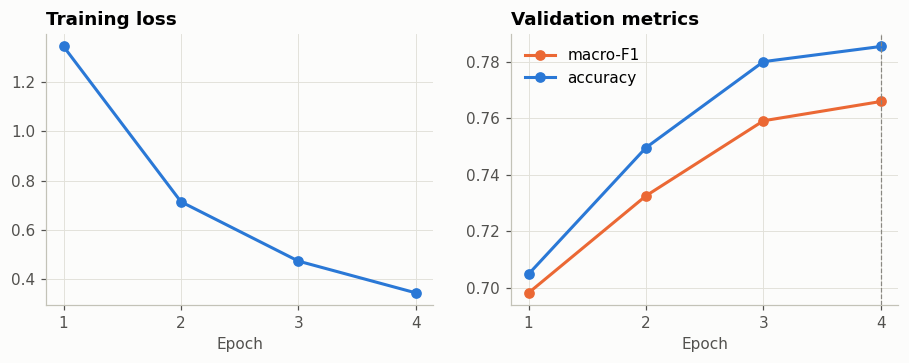

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(history.index, history["train_loss"], marker="o", color=BLUE, lw=2)
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[1].plot(history.index, history["val_macro_f1"], marker="o", color=ORANGE, lw=2, label="macro-F1")
axes[1].plot(history.index, history["val_accuracy"], marker="o", color=BLUE, lw=2, label="accuracy")
axes[1].axvline(best_epoch, color=GRAY, ls="--", lw=0.8)
axes[1].set_title("Validation metrics")
axes[1].set_xlabel("Epoch")
axes[1].legend()
for ax in axes:
    ax.set_xticks(history.index)
save("13_distilbert_training")
plt.show()

### A.1 Test-set evaluation and head-to-head comparison

In [8]:
test_logits, test_true = predict(test_dl)
test_probs = torch.softmax(test_logits, dim=1).numpy()
test_pred = test_probs.argmax(1)

bert_acc = accuracy_score(test_true, test_pred)
bert_macro = f1_score(test_true, test_pred, average="macro")
bert_weighted = f1_score(test_true, test_pred, average="weighted")
print(f"DistilBERT TEST accuracy {bert_acc:.3f} | macro-F1 {bert_macro:.3f} | weighted-F1 {bert_weighted:.3f}\n")
print(classification_report(test_true, test_pred, labels=range(len(LABELS)), target_names=LABELS, digits=3, zero_division=0))

DistilBERT TEST accuracy 0.789 | macro-F1 0.767 | weighted-F1 0.789

                precision    recall  f1-score   support

          CASA      0.798     0.813     0.805       331
  Credit Cards      0.799     0.782     0.791       321
Credit Reports      0.779     0.740     0.759       219
         Loans      0.794     0.783     0.788       221
      Mortgage      0.876     0.912     0.893       170
        Others      0.673     0.686     0.680        51
    Remittance      0.626     0.679     0.651        84

      accuracy                          0.789      1397
     macro avg      0.764     0.771     0.767      1397
  weighted avg      0.789     0.789     0.789      1397



In [9]:
tfidf_metrics = json.loads((OUT_DIR / "tfidf_metrics.json").read_text())
bert_report = classification_report(test_true, test_pred, labels=range(len(LABELS)), target_names=LABELS,
                                    output_dict=True, zero_division=0)
bert_metrics = {
    "model": f"Fine-tuned {CLASSIFIER_CHECKPOINT}", "best_epoch": best_epoch, "max_len": MAX_LEN,
    "test_accuracy": round(bert_acc, 4), "test_macro_f1": round(bert_macro, 4), "test_weighted_f1": round(bert_weighted, 4),
    "per_class_f1": {l: round(bert_report[l]["f1-score"], 4) for l in LABELS}, "quick_run": QUICK_RUN,
}
(OUT_DIR / "transformer_metrics.json").write_text(json.dumps(bert_metrics, indent=2))

comparison = pd.DataFrame({
    tfidf_metrics["model"]: {k: tfidf_metrics[k] for k in ["test_accuracy", "test_macro_f1", "test_weighted_f1"]},
    bert_metrics["model"]: {k: bert_metrics[k] for k in ["test_accuracy", "test_macro_f1", "test_weighted_f1"]},
}).T
comparison["Δ vs TF-IDF (macro-F1)"] = comparison["test_macro_f1"] - tfidf_metrics["test_macro_f1"]
comparison.round(3)

,test_accuracy,test_macro_f1,test_weighted_f1,Δ vs TF-IDF (macro-F1)
TF-IDF + Logistic Regression,0.788,0.734,0.784,0.000
Fine-tuned distilbert-base-uncased,0.789,0.767,0.789,0.033


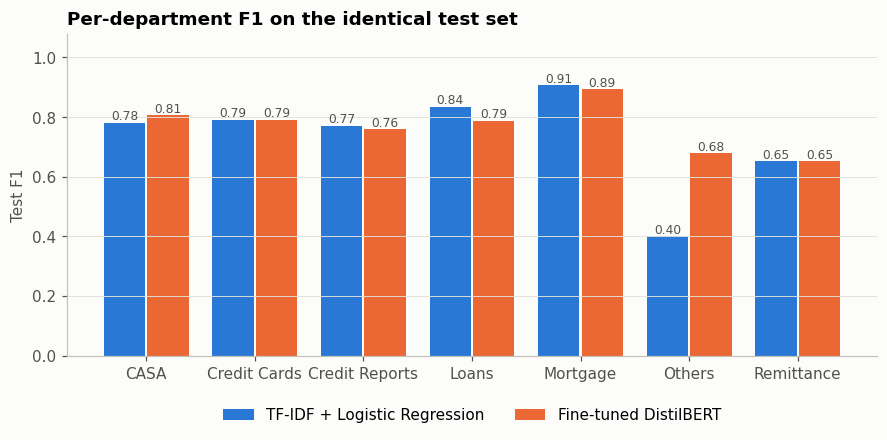

In [10]:
per_class = pd.DataFrame({"TF-IDF + LR": tfidf_metrics["per_class_f1"], "DistilBERT": bert_metrics["per_class_f1"]}).loc[LABELS]
fig, ax = plt.subplots(figsize=(9.5, 3.8))
x = np.arange(len(LABELS))
w = 0.38
b1 = ax.bar(x - w/2 - 0.01, per_class["TF-IDF + LR"], w, color=BLUE, label="TF-IDF + Logistic Regression")
b2 = ax.bar(x + w/2 + 0.01, per_class["DistilBERT"], w, color=ORANGE, label="Fine-tuned DistilBERT")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f"{b.get_height():.2f}", ha="center", fontsize=8,
                color="#52514e")
ax.set_xticks(x, LABELS)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Test F1")
ax.set_title("Per-department F1 on the identical test set")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="x", visible=False)
save("14_tfidf_vs_distilbert_f1")
plt.show()

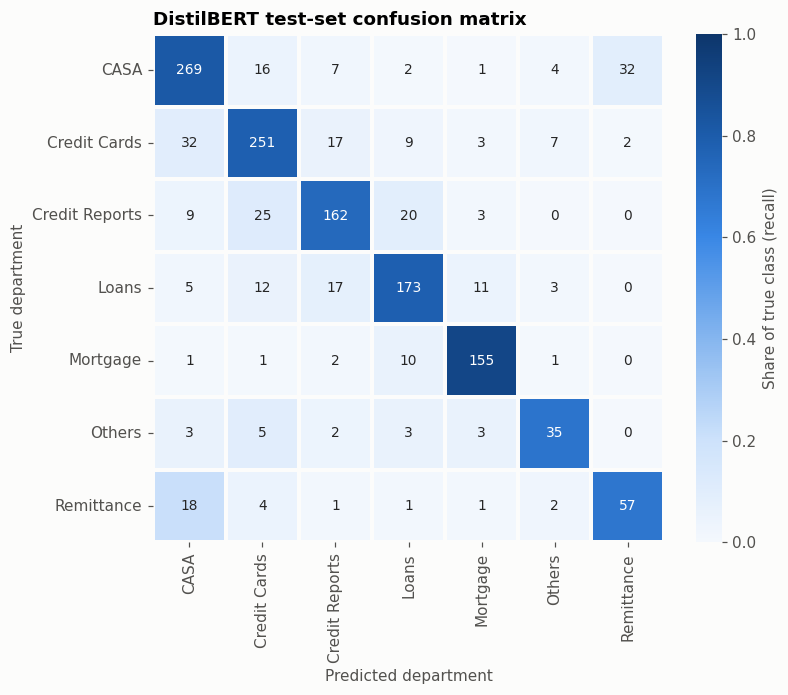

DistilBERT triage trade-off (softmax confidence; compare with notebook 01, Section 4.1):


,auto-routed share,accuracy on auto-routed
confidence ≥,,
0.500000,94.8%,81.2%
0.600000,88.7%,83.7%
0.700000,83.5%,85.8%
0.800000,76.7%,86.7%
0.900000,61.7%,90.5%


In [11]:
cm = confusion_matrix(test_true, test_pred, labels=range(len(LABELS)))
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(cm / cm.sum(axis=1, keepdims=True).clip(min=1), annot=cm, fmt="d", cmap=SEQ_BLUE, vmin=0, vmax=1,
            xticklabels=LABELS, yticklabels=LABELS, linewidths=1.5, linecolor="#fcfcfb",
            cbar_kws={"label": "Share of true class (recall)"}, ax=ax, annot_kws={"fontsize": 9})
ax.set_xlabel("Predicted department")
ax.set_ylabel("True department")
ax.set_title("DistilBERT test-set confusion matrix")
ax.grid(False)
save("15_distilbert_confusion_matrix")
plt.show()

conf = test_probs.max(1)
triage = pd.DataFrame([{"confidence ≥": t, "auto-routed share": (conf >= t).mean(),
                        "accuracy on auto-routed": accuracy_score(test_true[conf >= t], test_pred[conf >= t]) if (conf >= t).any() else np.nan}
                       for t in [0.5, 0.6, 0.7, 0.8, 0.9]]).set_index("confidence ≥")
print("DistilBERT triage trade-off (softmax confidence; compare with notebook 01, Section 4.1):")
triage.style.format({"auto-routed share": "{:.1%}", "accuracy on auto-routed": "{:.1%}"})

In [12]:
# Plain-language read-out of Part A, generated from the numbers above
delta = bert_macro - tfidf_metrics["test_macro_f1"]
better = [l for l in LABELS if per_class.loc[l, "DistilBERT"] > per_class.loc[l, "TF-IDF + LR"] + 0.01]
worse = [l for l in LABELS if per_class.loc[l, "DistilBERT"] < per_class.loc[l, "TF-IDF + LR"] - 0.01]
verdict = ("outperforms" if delta > 0.01 else "underperforms" if delta < -0.01 else "matches")
print(f"DistilBERT {verdict} the TF-IDF baseline on macro-F1 ({bert_macro:.3f} vs {tfidf_metrics['test_macro_f1']:.3f}, "
      f"{delta:+.3f}) and scores {bert_acc:.1%} accuracy vs {tfidf_metrics['test_accuracy']:.1%}.")
print("Departments where DistilBERT is clearly better:", ", ".join(better) or "none")
print("Departments where TF-IDF is clearly better:   ", ", ".join(worse) or "none")

DistilBERT outperforms the TF-IDF baseline on macro-F1 (0.767 vs 0.734, +0.033) and scores 78.9% accuracy vs 78.8%.
Departments where DistilBERT is clearly better: CASA, Others
Departments where TF-IDF is clearly better:    Credit Reports, Loans, Mortgage


**Part A results**

| | TF-IDF + LR | DistilBERT |
|---|---|---|
| Test accuracy | 78.8% | 78.9% |
| Test macro-F1 | 0.734 | **0.767** |
| Others F1 | 0.400 | **0.680** |
| CASA F1 | 0.781 | **0.805** |
| Mortgage F1 | **0.907** | 0.893 |
| Loans F1 | **0.835** | 0.788 |
| Credit Reports F1 | **0.771** | 0.759 |
| Remittance F1 | 0.651 | 0.651 |

* **Overall accuracy is a tie. The gain is in the hard, small class.** Macro-F1 rises 3.3 points because DistilBERT nearly doubles the F1 on **Others** (0.40 → 0.68) and also improves CASA. In notebook 01 I called the Others ↔ CASA confusion a taxonomy ceiling. That turns out to be only partly true. A contextual model recovers a good share of the difference, probably from cues that bag-of-words averages away: the names of *other* banks that appear unmasked in Others complaints, and the phrasing of the older complaint form. The class-weighted loss also helps the small class.
* **TF-IDF still wins where the vocabulary is distinctive.** Mortgage, Loans and Credit Reports have strong keywords (*escrow, collector, Equifax*), so bag-of-words is already enough. Truncating at 384 tokens may also cost DistilBERT on Mortgage, which has the longest complaints.
* **Remittance is unchanged (0.65) for both models.** Zelle and wire complaints really are checking-account complaints too, so that's the true label-overlap problem.
* **Training hadn't plateaued.** The best epoch was the last one (4 of 4), so 5-6 epochs would likely add a little more.
* **Production choice:** TF-IDF + Logistic Regression matches DistilBERT on overall accuracy, trains in seconds on a CPU, and is explainable term by term. DistilBERT earns its GPU cost only if routing the small classes correctly matters. Merging the legacy Others label into CASA (recommended in notebook 01) would remove most of DistilBERT's advantage. A reasonable setup is TF-IDF as the primary router, with DistilBERT as a second opinion on complaints the TF-IDF model isn't confident about.

## Part B. Transformer sentiment vs. VADER

Notebook 01 found that out-of-the-box VADER misreads banking vocabulary, and that its compound score saturates on long texts. To check the domain-adjusted VADER scores independently, I run **`cardiffnlp/twitter-roberta-base-sentiment-latest`**, a RoBERTa model trained on about 124M tweets and fine-tuned for negative / neutral / positive sentiment.

**Handling long complaints:** RoBERTa reads at most 512 tokens, and some complaints are much longer. Instead of truncating, each complaint is split into overlapping **512-token windows**, every window is scored, and the class probabilities are averaged (weighted by window length). That way the whole complaint counts toward the score.

**Score:** `transformer_score = P(positive) − P(negative)`, a continuous value in [-1, +1] that's directly comparable with VADER's compound score.

In [13]:
# free the classifier before loading the sentiment model
del model, optimizer
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

sent_tok = AutoTokenizer.from_pretrained(SENTIMENT_CHECKPOINT)
sent_model = AutoModelForSequenceClassification.from_pretrained(SENTIMENT_CHECKPOINT).to(DEVICE).eval()
names = {i: n.lower() for i, n in sent_model.config.id2label.items()}
IDX = {key: next(i for i, n in names.items() if n.startswith(key)) for key in ["neg", "neu", "pos"]}
print("Model labels:", sent_model.config.id2label)

sent_df = df if not QUICK_RUN else df.head(300)
WINDOW = min(512, getattr(sent_tok, "model_max_length", 512) or 512)

@torch.no_grad()
def score_documents(texts, batch_docs=16):
    out = np.zeros((len(texts), 3))
    for start in range(0, len(texts), batch_docs):
        chunk = texts[start:start + batch_docs]
        enc = sent_tok(chunk, truncation=True, max_length=WINDOW, stride=64, return_overflowing_tokens=True,
                       padding=True, return_tensors="pt")
        mapping = enc.pop("overflow_to_sample_mapping").numpy()
        lengths = enc["attention_mask"].sum(1).numpy()
        enc = {k: v.to(DEVICE) for k, v in enc.items() if k in ("input_ids", "attention_mask")}
        probs = []
        for s in range(0, enc["input_ids"].shape[0], 32):          # keep window batches GPU-sized
            with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                logits = sent_model(**{k: v[s:s + 32] for k, v in enc.items()}).logits
            probs.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
        probs = np.vstack(probs)
        for d in range(len(chunk)):
            m = mapping == d
            p = np.average(probs[m], axis=0, weights=lengths[m])
            out[start + d] = [p[IDX["neg"]], p[IDX["neu"]], p[IDX["pos"]]]
    return out

t0 = time.perf_counter()
P = score_documents(sent_df["text"].tolist())
print(f"Scored {len(sent_df):,} complaints in {(time.perf_counter() - t0)/60:.1f} min")

sent = sent_df[["Complaint ID", "Department", "Bank Response"]].copy()
sent[["tf_neg", "tf_neu", "tf_pos"]] = P
sent["transformer_score"] = sent["tf_pos"] - sent["tf_neg"]
sent["transformer_label"] = np.array(["Negative", "Neutral", "Positive"])[P.argmax(1)]

vader = pd.read_csv(OUT_DIR / "complaints_scored.csv", dtype={"Complaint ID": str})
sent = sent.merge(vader[["Complaint ID", "vader_compound", "sent_compound", "sent_label", "severity"]], on="Complaint ID")
sent.to_csv(OUT_DIR / "transformer_sentiment.csv", index=False)
sent[["tf_neg", "tf_neu", "tf_pos", "transformer_score"]].describe().round(3)

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

...

Model labels: {0: 'negative', 1: 'neutral', 2: 'positive'}


model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

Scored 7,011 complaints in 0.5 min


,tf_neg,tf_neu,tf_pos,transformer_score
count,7011.000,7011.000,7011.000,7011.000
mean,0.590,0.382,0.028,-0.562
std,0.246,0.221,0.051,0.277
min,0.003,0.051,0.004,-0.937
25%,0.422,0.200,0.010,-0.781
50%,0.660,0.323,0.015,-0.645
75%,0.790,0.537,0.027,-0.390
max,0.943,0.940,0.865,0.862


In [14]:
dist = pd.DataFrame({
    "VADER (out of the box)": pd.cut(sent["vader_compound"], [-1.01, -0.05, 0.05, 1.01], labels=["Negative", "Neutral", "Positive"]).value_counts(normalize=True),
    "VADER (domain-adjusted)": sent["sent_label"].value_counts(normalize=True),
    "RoBERTa transformer": sent["transformer_label"].value_counts(normalize=True),
}).reindex(["Negative", "Neutral", "Positive"]).fillna(0)
display(dist.style.format("{:.1%}"))

rho_raw = spearmanr(sent["vader_compound"], sent["transformer_score"]).correlation
rho_adj = spearmanr(sent["sent_compound"], sent["transformer_score"]).correlation
agree = (sent["sent_label"] == sent["transformer_label"]).mean()
print(f"Spearman correlation with transformer score: VADER raw {rho_raw:.3f} | VADER domain-adjusted {rho_adj:.3f}")
print(f"Label agreement, domain-adjusted VADER vs transformer: {agree:.1%}")
pd.crosstab(sent["sent_label"], sent["transformer_label"], margins=True)

,VADER (out of the box),VADER (domain-adjusted),RoBERTa transformer
Negative,54.5%,80.0%,69.8%
Neutral,4.5%,7.8%,29.8%
Positive,41.0%,12.2%,0.4%


Spearman correlation with transformer score: VADER raw 0.220 | VADER domain-adjusted 0.096
Label agreement, domain-adjusted VADER vs transformer: 61.3%


transformer_label,Negative,Neutral,Positive,All
sent_label,,,,
Negative,4100,1493,13,5606
Neutral,360,185,2,547
Positive,433,413,12,858
All,4893,2091,27,7011


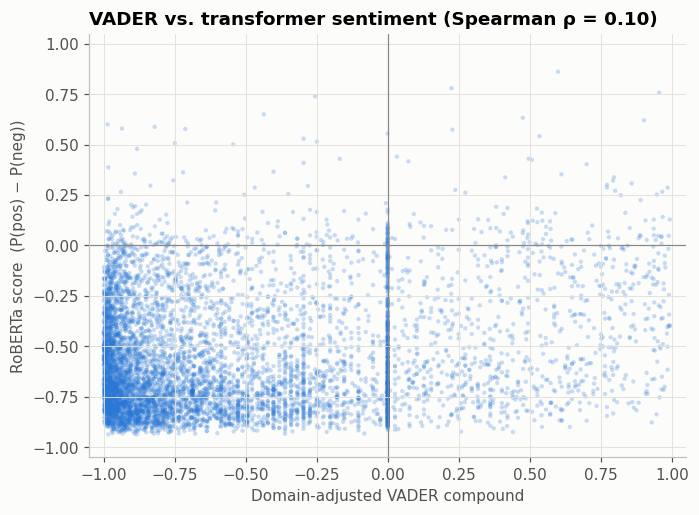

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(sent["sent_compound"], sent["transformer_score"], s=8, alpha=0.25, color=BLUE, edgecolor="none")
ax.axhline(0, color=GRAY, lw=0.8)
ax.axvline(0, color=GRAY, lw=0.8)
ax.set_xlabel("Domain-adjusted VADER compound")
ax.set_ylabel("RoBERTa score  (P(pos) − P(neg))")
ax.set_title(f"VADER vs. transformer sentiment (Spearman ρ = {rho_adj:.2f})")
ax.set_xlim(-1.05, 1.05)
ax.set_ylim(-1.05, 1.05)
save("16_vader_vs_transformer")
plt.show()

In [16]:
sent["monetary_relief"] = sent["Bank Response"].eq("Closed with monetary relief")
sent["tf_quintile"] = pd.qcut(sent["transformer_score"].rank(method="first"), 5,
                              labels=["Q1 most negative", "Q2", "Q3", "Q4", "Q5 least negative"])
summary = pd.DataFrame({
    "mean transformer score": sent.groupby("Department")["transformer_score"].mean(),
    "mean VADER (adjusted)": sent.groupby("Department")["sent_compound"].mean(),
    "transformer % negative": sent.groupby("Department")["transformer_label"].apply(lambda s: (s == "Negative").mean()),
}).sort_values("mean transformer score")
display(summary.style.format({"mean transformer score": "{:+.3f}", "mean VADER (adjusted)": "{:+.3f}",
                              "transformer % negative": "{:.1%}"}))
print("Monetary-relief rate by transformer-score quintile:")
sent.groupby("tf_quintile", observed=True)["monetary_relief"].mean().to_frame("monetary relief rate").style.format("{:.1%}")

,mean transformer score,mean VADER (adjusted),transformer % negative
Department,,,
Credit Reports,-0.643,-0.518,82.3%
Loans,-0.601,-0.534,74.0%
CASA,-0.554,-0.567,68.5%
Credit Cards,-0.538,-0.544,67.6%
Mortgage,-0.520,-0.458,62.3%
Remittance,-0.495,-0.601,61.1%
Others,-0.484,-0.469,59.1%


Monetary-relief rate by transformer-score quintile:


,monetary relief rate
tf_quintile,
Q1 most negative,15.5%
Q2,16.3%
Q3,19.0%
Q4,19.7%
Q5 least negative,18.7%


In [17]:
# Plain-language read-out of Part B, generated from the numbers above
neg_tf, neg_v = dist.loc["Negative", "RoBERTa transformer"], dist.loc["Negative", "VADER (domain-adjusted)"]
pos_tf, pos_v = dist.loc["Positive", "RoBERTa transformer"], dist.loc["Positive", "VADER (domain-adjusted)"]
print(f"The transformer labels {neg_tf:.0%} of complaints negative and {pos_tf:.0%} positive "
      f"(domain-adjusted VADER: {neg_v:.0%} / {pos_v:.0%}; out-of-the-box VADER: "
      f"{dist.loc['Negative', 'VADER (out of the box)']:.0%} / {dist.loc['Positive', 'VADER (out of the box)']:.0%}).")
print(f"Rank agreement with the transformer {'improves' if rho_adj > rho_raw else 'does not improve'} after the VADER "
      f"domain adjustment (ρ {rho_raw:.2f} -> {rho_adj:.2f}).")
rank_tf = summary["mean transformer score"].rank()
rank_v = summary["mean VADER (adjusted)"].rank()
print(f"Department ranking agreement (Spearman over 7 departments): {spearmanr(rank_tf, rank_v).correlation:.2f}")

The transformer labels 70% of complaints negative and 0% positive (domain-adjusted VADER: 80% / 12%; out-of-the-box VADER: 54% / 41%).
Rank agreement with the transformer does not improve after the VADER domain adjustment (ρ 0.22 -> 0.10).
Department ranking agreement (Spearman over 7 departments): 0.07


**Part B results**

| | Negative | Neutral | Positive |
|---|---|---|---|
| VADER, out of the box | 54% | 5% | 41% |
| VADER, domain-adjusted | 80% | 8% | 12% |
| RoBERTa transformer | 70% | ~30% | ~0% |

* **The transformer confirms the main lexicon finding.** RoBERTa reads context instead of a word list and calls essentially **no** complaint positive. Out-of-the-box VADER's 41% "positive" was an artifact of words like *credit*, *interest* and *please help*. The domain-adjusted version (12% positive) moves in the right direction.
* **RoBERTa's ~30% neutral** fits the many calm, procedural complaints (dispute letters, documentation requests) that report a problem without emotional language.
* **Ranking agreement is weak, though.** Spearman ρ between the two scores is only **0.22 (raw VADER) and 0.10 (adjusted)**, and the two methods barely agree on which departments are most negative (ρ 0.07 across the 7 departments). The domain adjustment fixed VADER's labels but didn't improve its ranking. A likely reason is saturation: once the positive banking words are neutralized, many long complaints hit VADER's -1 floor and tie, while RoBERTa's window-averaged probabilities still separate them.
* **What it means for the business analysis.** Both methods agree that the complaints are overwhelmingly negative. They don't agree on *which* complaints are the worst. So notebook 01's severity tiers are a coarse flag, not a precise ranking, and the topic and department severity comparisons should be re-checked with `transformer_score` (saved in `outputs/transformer_sentiment.csv`) before anyone acts on them.
* **Recommendation.** Hand-label a few hundred complaints for severity and see which score tracks human judgment better. On paper the transformer is the stronger severity measure for long, formal complaints, since it doesn't saturate. VADER stays useful as a fast, explainable first pass that runs on a CPU in seconds.